In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state,pos_space,vel_space,ang_space,ang_vel_space):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class IncrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [4]:
class DecrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=(self.goal - abs(self.goal-result))/self.goal
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)"""

In [5]:
class STDQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.std=20
        self.goal=goal
        
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        if result < self.goal-self.std:
            reward=1
        elif result > self.goal+self.std:
            reward=-1
        else:
            reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            """if i < goal-10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)
                continue
            if i > goal+10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                continue"""
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [6]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [7]:
class expQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal,p=2):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        self.p=p
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        k=0.01
        p=self.p
        if value < 0:
            return - abs((((1+k*value)**p)-1)/p)
        return (((1+k*value)**p)-1)/p
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [8]:
def uniTraining(goal,episodeNumber=30000,type="inc",p=2):
    timeSteps=10000
    episodesResults=[]
    episodesTestResults=[]
    episodesTestResultsDeviation=[]
    numberOfTest=50
    if type == "inc":
        qagent= IncrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "dec":
        qagent= DecrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "std":
        qagent= STDQlearning(0.1,0.99,0.1,2,goal)
    elif type == "base":
        qagent= Qlearning(0.1,0.99,0.1,2,goal)
    elif type == "exp":
        qagent= expQlearning(0.1,0.99,0.1,2,goal,p)
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)

    for episodeIndex in range(episodeNumber):
       
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        #print("episode: ",episodeIndex)
        episodeObservation=[]
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation.append([tuple(state),action,tuple(next_state)])
            #qagent.update(tuple(state),action,tuple(next_state),reward)
            state=next_state
            if (terminated):
                #print("Number of steps :",timeIndex)
                
                episodesResults.append(timeIndex)
                break
    
        qagent.episodeRewards(episodeObservation)
        if(episodeIndex %500 ==0):
            qagent.epsilon=0
            testResultList=[]
            for episodeIndex in range(numberOfTest):
        
                state,_=env.reset()
                state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
                for timeIndex in range(timeSteps):
                    action=qagent.getAction(tuple(state))
                    next_state, reward, terminated, truncated, info =env.step(action)
                    next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                    state=next_state
                    if (terminated):
                        testResultList.append(timeIndex)
                        break
    
            episodesTestResults.append(sum(testResultList)/len(testResultList))
            episodesTestResultsDeviation.append(np.std(episodesTestResults))
            qagent.epsilon=0.1
        
    
    
    env.close() 
    return episodesResults,episodesTestResults,episodesTestResultsDeviation,qagent

In [9]:
def uniTest(agent,epsilon=0):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

In [10]:
distancetomeanAll=[]
for p in range(3,10):
    distancetomean=[]
    for goal in range(60,170,10):
        _,_,_,agent=uniTraining(goal,episodeNumber=10000,type="exp",p=p/2)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=0)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll.append(distancetomean)

60 92.78999999999999 39.57410302111991
70 74.8885 9.007756471023061
80 121.4176 26.9406745142862
90 113.2194 3.532957041314984
100 106.78009999999999 2.8291665842285285
110 55.245799999999996 50.32042885138942
120 107.7144 8.277847749765513
130 131.7897 6.3246816536771595
140 114.7203 4.16137597677073
150 134.5686 6.231268259344022
160 135.1882 6.1794957205396575
60 80.7099 24.052428485788447
70 435.1888 267.61240117919084
80 109.3362 9.111736161149958
90 108.6828 4.243236632908268
100 101.9438 14.175726420321492
110 109.32539999999999 4.364174907954576
120 113.85329999999999 5.253272054122336
130 27.4212 35.31066612623991
140 130.14900000000003 5.415287493358887
150 140.5344 4.772212845992181
160 139.0095 5.273180823482975
60 73.69800000000001 5.863485924075603
70 185.13860000000003 11.378838166952528
80 91.49960000000002 21.646846249630947
90 105.8653 3.006592649578489
100 109.6392 6.503821310293785
110 109.63250000000001 3.315872631736947
120 125.21450000000002 4.903900078435204
130

0.5464999999999999
5.216982857142857
1.644837142857143
1.8754011111111109
0.9347628571428568
1.9888571428571433
0.47580750000000016


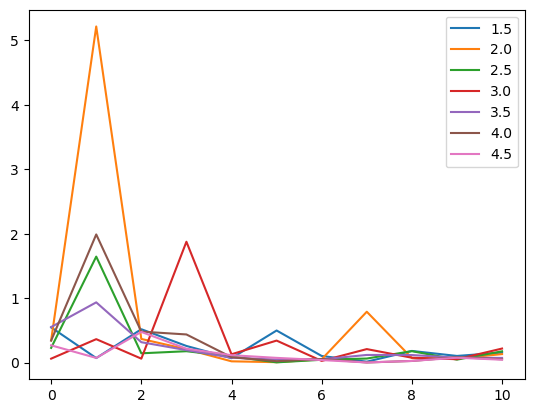

In [17]:

for i in distancetomeanAll:
    plt.plot(i)
    print(max(i))
plt.legend([x/2 for x in range(3,10)])

5.216982857142857